# 01 · EDA & klasifikasi demand — Walmart M5 (toko CA_1)

**Tujuan notebook:** memahami pola penjualan sebelum membangun model, lalu menerjemahkan setiap temuan menjadi keputusan desain untuk fase modeling.

**Aturan data di notebook ini:**
- Hanya memakai data **sampai d_1913** (2016-04-24). Periode test (d_1914–d_1941) **tidak dimuat sama sekali** supaya keputusan model tidak dipengaruhi oleh "mengintip" test set.
- Klasifikasi demand (Q6) dihitung hanya dari data **sampai d_1801** (akhir train fold pertama), supaya kelas item tidak bocor dari periode validasi mana pun.
- Hari toko tutup (Natal) dikeluarkan dari semua perhitungan.
- Semua fungsi plot diimpor dari `src/forecasting/viz/plots.py`. Figur disimpan ke `reports/figures/` untuk README.

Data berasal dari `data/interim/sales_long.parquet` (hasil `scripts.make_dataset`) dan `data/processed/item_classes.parquet` (hasil `scripts.classify_demand`).

In [1]:
import numpy as np
import pandas as pd
import plotly.io as pio

from forecasting.config import load_config, resolve_path
from forecasting.data.load import store_overview
from forecasting.viz import plots

pio.renderers.default = "png"  # static images: readable on GitHub, small notebook
pio.renderers["png"].width = 1000
pd.set_option("display.float_format", "{:,.2f}".format)

config = load_config()
LAST_D = config["backtest"]["folds"][-1][2]  # d_1913 -> the test period is never loaded
CLASS_CUTOFF = config["backtest"]["folds"][0][0]  # d_1801 -> demand classes use data up to here
STORE = config["scope"]["store_id"]

sales = pd.read_parquet(
    resolve_path(config, "interim") / "sales_long.parquet", filters=[("d", "<=", LAST_D)]
)
classes = pd.read_parquet(resolve_path(config, "processed") / "item_classes.parquet")
open_sales = sales[sales["is_closed"] == 0]  # drop Christmas (store closed)

print(
    f"{STORE}: {sales['item_id'].nunique():,} item | d_{sales['d'].min()}..d_{sales['d'].max()} "
    f"| {sales['date'].min().date()} -> {sales['date'].max().date()} | {len(sales):,} baris"
)

CA_1: 3,049 item | d_1..d_1913 | 2011-01-29 -> 2016-04-24 | 4,702,895 baris


## Q1 · Tren & level penjualan toko

**Insight:** Level penjualan CA_1 naik dari ±3.160 unit/hari (2011) menjadi ±4.410 unit/hari (2015), tetapi pertumbuhannya **melambat tajam**: +22% (2012) → +10% → +2,6% → +1,8% → praktis 0% di 2016. Tidak terlihat *structural break* (lonjakan level permanen): perubahan terbesar antar-blok 28 hari hanya ±8–10% dan semuanya berulang di musim yang sama (turun di akhir tahun, naik di musim semi/panas).

> *Structural break* = perubahan level atau pola yang permanen (misalnya toko direnovasi atau diperluas). Kalau ada, data sebelum break bisa menyesatkan model.

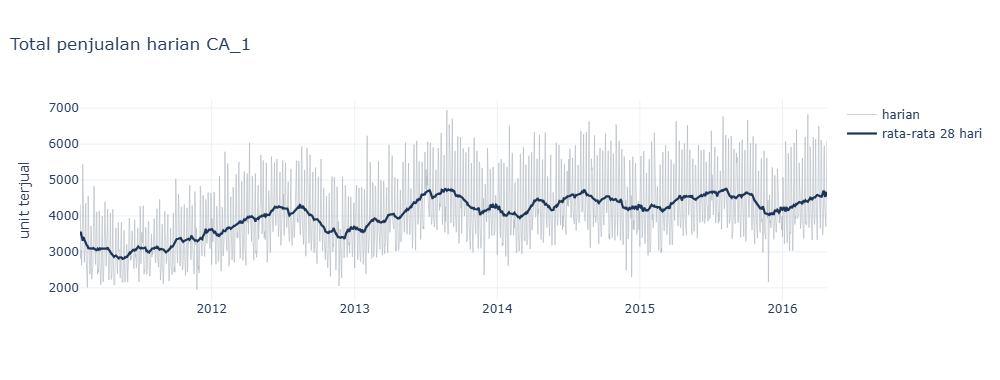

,units,days,units_per_day,growth_pct
year,,,,
2011,1060793,336,"3,157.12",NaN
2012,1406432,365,"3,853.24",22.05
2013,1538540,364,"4,226.76",9.69
2014,1577931,364,"4,334.98",2.56
2015,1606863,364,"4,414.46",1.83
2016,507657,115,"4,414.41",-0.00


In [2]:
store_daily = open_sales.groupby("date", as_index=False)["sales"].sum()
fig = plots.plot_daily_with_trend(store_daily, title=f"Total penjualan harian {STORE}")
fig.show()
plots.save_png(fig, "01_store_trend", config)

by_year = open_sales.groupby("year").agg(units=("sales", "sum"), days=("date", "nunique"))
by_year["units_per_day"] = by_year["units"] / by_year["days"]
by_year["growth_pct"] = by_year["units_per_day"].pct_change() * 100
by_year

In [3]:
# Structural-break check: largest jumps between consecutive 28-day blocks
blocks = store_daily.set_index("date")["sales"].resample("28D").mean()
jumps = (blocks.pct_change() * 100).rename("change_pct")
jumps.abs().sort_values(ascending=False).head(5).index.to_series().map(
    lambda t: f"{t.date()}: {jumps[t]:+.1f}% (level {blocks[t]:,.0f}/hari)"
).to_list()

['2014-03-22: +9.7% (level 4,406/hari)',
 '2011-12-03: +9.1% (level 3,619/hari)',
 '2015-10-31: -8.7% (level 4,164/hari)',
 '2011-04-23: -8.5% (level 2,848/hari)',
 '2012-10-06: -8.2% (level 3,574/hari)']

## Q2 · Seasonality mingguan & tahunan

> **Seasonality** = pola yang berulang dengan periode tetap. Di sini dicek dua periode: mingguan (7 hari) dan tahunan (12 bulan). Angka ditampilkan sebagai indeks: 1,25 berarti 25% di atas rata-rata.

**Insight mingguan:** pola mingguan **sangat kuat dan konsisten di semua kategori**. Sabtu–Minggu 11–34% di atas rata-rata, sedangkan Selasa–Kamis 10–20% di bawahnya. Selisih akhir pekan vs tengah minggu mencapai ±50%.

**Insight tahunan (2012–2015, dinormalisasi per tahun):** pola tahunan lebih lemah, ±8–18%. Januari–Februari paling rendah (HOUSEHOLD Januari −18%), dan puncaknya Juni–September (FOODS Agustus +10%, HOUSEHOLD Agustus +12%). HOBBIES hampir datar sepanjang tahun.

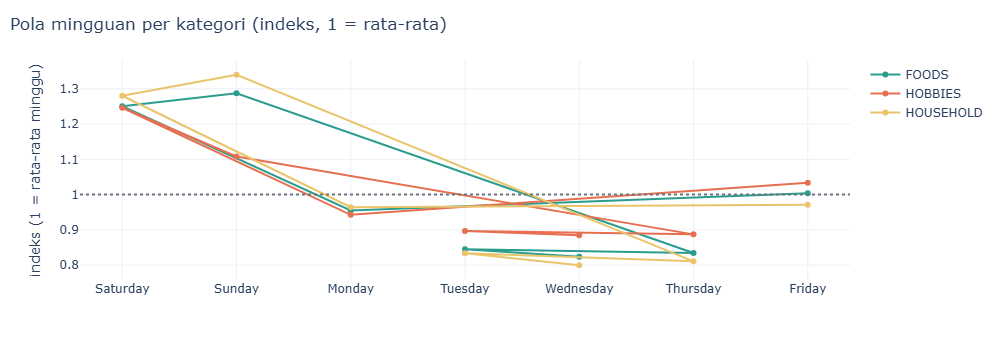

cat_id,FOODS,HOBBIES,HOUSEHOLD
weekday,,,
Saturday,1.25,1.25,1.28
Sunday,1.29,1.11,1.34
Monday,0.96,0.94,0.96
Tuesday,0.85,0.90,0.83
Wednesday,0.82,0.88,0.80
Thursday,0.83,0.89,0.81
Friday,1.00,1.03,0.97


In [4]:
cat_daily = open_sales.groupby(["date", "cat_id"], observed=True, as_index=False)["sales"].sum()
cat_daily["weekday"] = cat_daily["date"].dt.day_name()
cat_daily["month"] = cat_daily["date"].dt.month
cat_daily["year"] = cat_daily["date"].dt.year

wk = cat_daily.groupby(["cat_id", "weekday"], observed=True)["sales"].mean()
wk = (wk / wk.groupby(level=0).transform("mean")).rename("index").reset_index()
fig = plots.plot_weekday_profile(wk, title="Pola mingguan per kategori (indeks, 1 = rata-rata)")
fig.show()
plots.save_png(fig, "02a_weekday_profile", config)
wk.pivot(index="weekday", columns="cat_id", values="index").reindex(plots.WEEKDAYS)

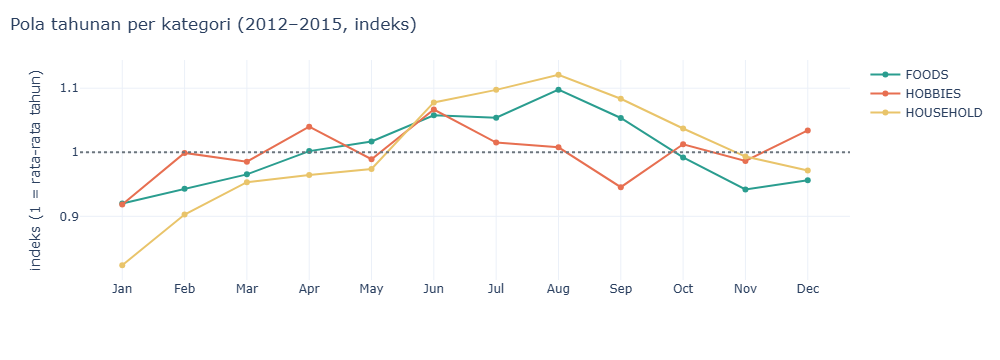

cat_id,FOODS,HOBBIES,HOUSEHOLD
month,,,
1,0.92,0.92,0.82
2,0.94,1.00,0.90
3,0.97,0.98,0.95
4,1.00,1.04,0.96
5,1.02,0.99,0.97
6,1.06,1.07,1.08
7,1.05,1.01,1.10
8,1.10,1.01,1.12
9,1.05,0.94,1.08


In [5]:
# Yearly pattern: full years only, normalised within each year to remove the trend
full = cat_daily[cat_daily["year"].between(2012, 2015)]
mo = full.groupby(["cat_id", "year", "month"], observed=True)["sales"].mean()
mo = mo / mo.groupby(level=[0, 1]).transform("mean")
mo = mo.groupby(level=[0, 2]).mean().rename("index").reset_index()
fig = plots.plot_month_profile(mo, title="Pola tahunan per kategori (2012–2015, indeks)")
fig.show()
plots.save_png(fig, "02b_month_profile", config)
mo.pivot(index="month", columns="cat_id", values="index").round(3)

## Q3 · Efek event & SNAP pada FOODS

> **SNAP** = program bantuan pangan pemerintah AS (food stamps). Di California, dana SNAP cair pada tanggal 1–10 setiap bulan, sehingga hari SNAP berpotensi menaikkan belanja makanan.

Cara ukur efek event: penjualan FOODS pada hari event dibandingkan dengan rata-rata **hari yang sama (weekday sama)** 1–4 minggu sebelumnya yang bukan hari event. Dengan begitu, efek akhir pekan tidak tercampur ke efek event.

**Insight event:** efeknya **berbeda arah per event**, bukan sekadar "event = naik". Hari raya besar justru **menurunkan** penjualan FOODS di hari-H, misalnya Thanksgiving −22%, Halloween −19%, Tahun Baru −18%, Mother's Day −17%, dan Easter −15% (orang belanja sebelum hari-H, atau jam buka toko lebih pendek). Sebaliknya, Labor Day +30%, Columbus Day +12%, dan Veterans Day +11%. Catatan: setiap event hanya terjadi 4–6 kali, dan Labor Day (Senin pertama September) selalu jatuh di periode SNAP, jadi angkanya tercampur efek SNAP dan bukan efek murni.

**Insight SNAP:** dibandingkan dengan hari non-SNAP pada tahun, bulan, dan weekday yang sama, penjualan **FOODS +12,7%** di hari SNAP. HOBBIES dan HOUSEHOLD hanya ±+5%. Efeknya masuk akal karena dana SNAP hanya bisa dibelanjakan untuk makanan.

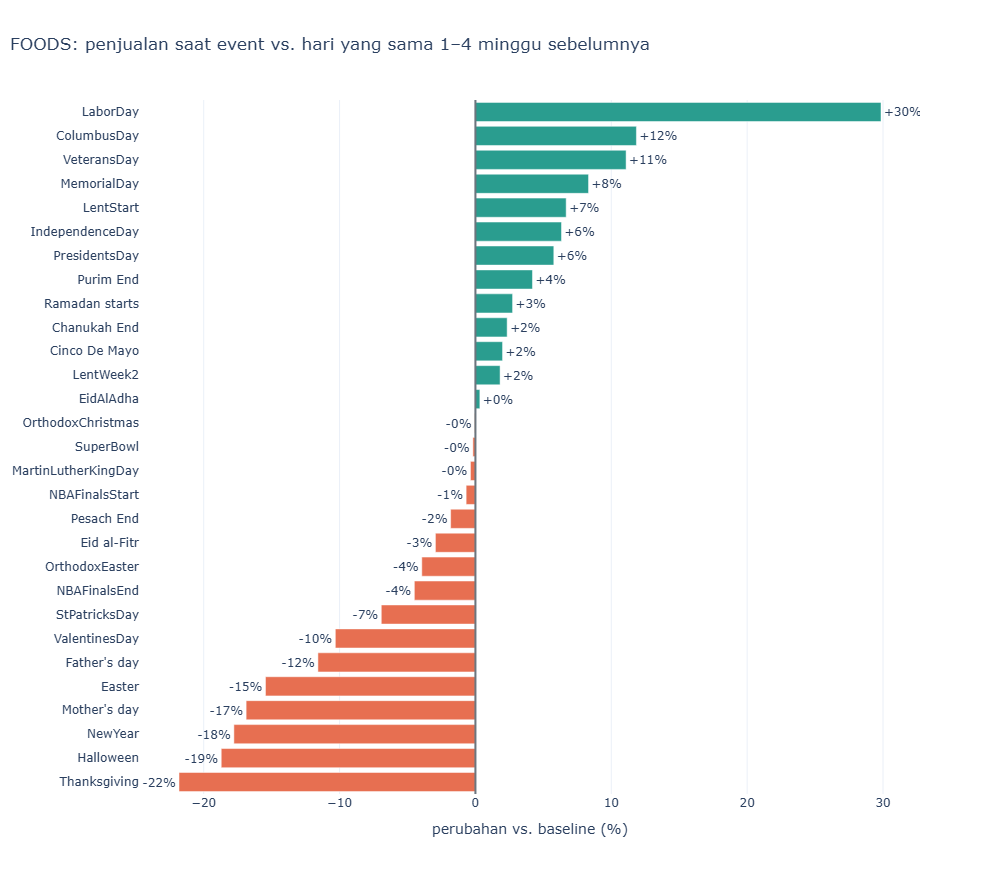

"              event  lift_pct  n_years\n       Thanksgiving    -21.80        5\n          Halloween    -18.70        5\n            NewYear    -17.80        5\n       Mother's day    -16.90        5\n             Easter    -15.50        5\n       Father's day    -11.60        4\n      ValentinesDay    -10.30        6\n      StPatricksDay     -6.90        6\n       NBAFinalsEnd     -4.50        5\n     OrthodoxEaster     -3.90        4\n        Eid al-Fitr     -2.90        5\n         Pesach End     -1.80        5\n     NBAFinalsStart     -0.70        5\nMartinLutherKingDay     -0.40        5\n          SuperBowl     -0.20        5\n  OrthodoxChristmas     -0.10        5\n          EidAlAdha      0.30        5\n          LentWeek2      1.80        6\n      Cinco De Mayo      2.00        4\n       Chanukah End      2.30        5\n     Ramadan starts      2.70        5\n          Purim End      4.20        6\n      PresidentsDay      5.80        6\n    IndependenceDay      6.30        5\

In [6]:
cal = sales.drop_duplicates("d").set_index("date")[["event_name_1", "event_type_1", "snap"]]
foods = cat_daily[cat_daily["cat_id"] == "FOODS"].set_index("date")["sales"]
event_days = set(cal.index[cal["event_name_1"].notna()])

rows = []
for day, ev in cal.loc[cal["event_name_1"].notna(), "event_name_1"].items():
    if day not in foods.index:
        continue  # closed day (Christmas)
    refs = [day - pd.Timedelta(weeks=k) for k in range(1, 5)]
    refs = [r for r in refs if r in foods.index and r not in event_days]
    if len(refs) >= 2:  # baseline = same weekday in the previous 4 weeks (non-event)
        rows.append({"event": ev, "lift": foods[day] / foods[refs].mean() - 1})
event_lift = (
    pd.DataFrame(rows)
    .groupby("event")["lift"]
    .agg(["mean", "size"])
    .rename(columns={"mean": "lift_pct", "size": "n_years"})
)
event_lift["lift_pct"] *= 100
event_lift = event_lift.reset_index()
fig = plots.plot_effect_bars(
    event_lift,
    "event",
    "lift_pct",
    title="FOODS: penjualan saat event vs. hari yang sama 1–4 minggu sebelumnya",
)
fig.show()
plots.save_png(fig, "03a_event_lift_foods", config)
event_lift.sort_values("lift_pct").round(1).to_string(index=False)

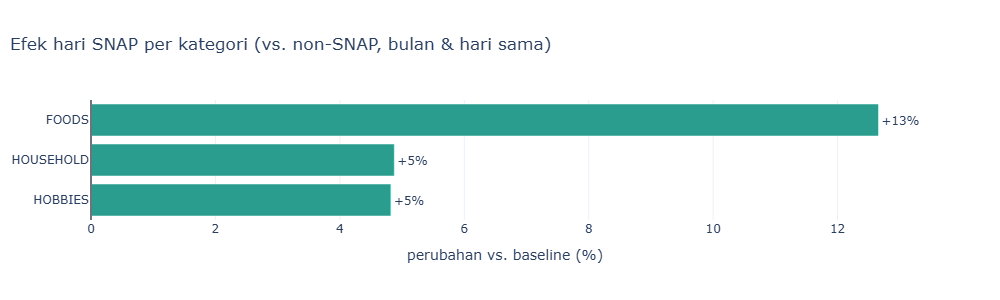

,cat_id,lift_pct
0,FOODS,12.70
1,HOBBIES,4.80
2,HOUSEHOLD,4.90


In [7]:
# SNAP: compare SNAP vs non-SNAP days within the same (year, month, weekday)
d = cat_daily.join(cal["snap"], on="date")
g = d.groupby(["cat_id", "year", "month", "weekday", "snap"], observed=True)["sales"].mean()
g = g.unstack("snap").dropna()
snap_lift = (g[1] / g[0] - 1).groupby("cat_id", observed=True).mean() * 100
snap_lift = snap_lift.rename("lift_pct").reset_index()
fig = plots.plot_effect_bars(
    snap_lift,
    "cat_id",
    "lift_pct",
    title="Efek hari SNAP per kategori (vs. non-SNAP, bulan & hari sama)",
)
fig.show()
plots.save_png(fig, "03b_snap_lift", config)
snap_lift.round(1)

## Q4 · Harga vs penjualan

Pendekatan: untuk setiap item-minggu, perubahan harga dibandingkan dengan minggu sebelumnya, dan unit terjual dibandingkan dengan rata-rata 4 minggu sebelumnya. Item yang hampir tidak laku (< 5 unit/minggu) diabaikan.

**Insight:** arah efeknya sesuai teori. Saat harga turun ≥5%, median unit **+8,5%**. Saat harga naik ≥5%, median unit **−16,7%**. Kelompok "harga tetap" sendiri bernilai −5,5% karena median data yang miring selalu di bawah rata-rata, jadi pembanding yang adil adalah selisih terhadap kelompok itu: turun harga ≈ **+14 poin**, naik harga ≈ **−11 poin**. Namun perubahan harga **jarang**: hanya ±2.000 dari ±325.000 item-minggu (±0,6%). Ini korelasi, bukan kausalitas.

Contoh di bawah (item dengan perubahan harga terbanyak dalam 2 tahun terakhir) menunjukkan bahwa di level satu item, hubungannya **tidak selalu rapi**. Variasi harian dan faktor lain (event, musim, stok) sering lebih besar daripada efek harga.

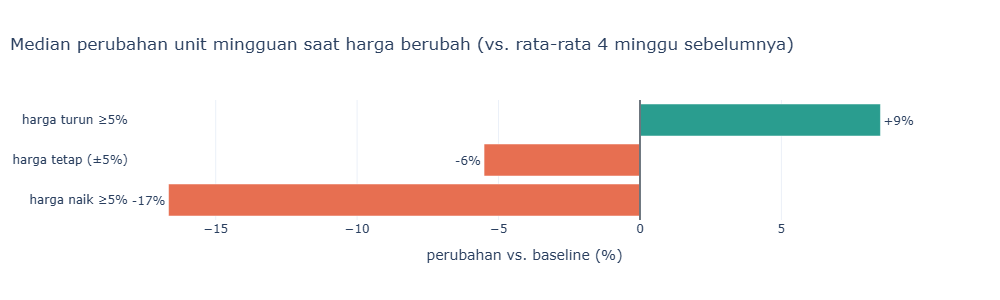

,bucket,n_weeks,median_chg_pct
0,harga turun ≥5%,642,8.50
1,harga tetap (±5%),323324,-5.50
2,harga naik ≥5%,1387,-16.70


In [8]:
wk_item = (
    open_sales.groupby(["item_id", "wm_yr_wk"], observed=True)
    .agg(units=("sales", "sum"), price=("sell_price", "mean"), days=("d", "size"))
    .reset_index()
)
wk_item = wk_item[wk_item["days"] == 7].sort_values(["item_id", "wm_yr_wk"])
grp = wk_item.groupby("item_id", observed=True)
wk_item["price_chg"] = grp["price"].pct_change()
wk_item["base_units"] = grp["units"].transform(
    lambda s: s.shift(1).rolling(4, min_periods=4).mean()
)
wk_item = wk_item.dropna(subset=["price_chg", "base_units"])
wk_item = wk_item[wk_item["base_units"] >= 5]  # ignore near-zero sellers

wk_item["bucket"] = pd.cut(
    wk_item["price_chg"],
    [-np.inf, -0.05, 0.05, np.inf],
    labels=["harga turun ≥5%", "harga tetap (±5%)", "harga naik ≥5%"],
)
wk_item["units_chg"] = wk_item["units"] / wk_item["base_units"] - 1
price_effect = (
    wk_item.groupby("bucket", observed=True)
    .agg(n_weeks=("units_chg", "size"), median_chg_pct=("units_chg", "median"))
    .reset_index()
)
price_effect["median_chg_pct"] *= 100
fig = plots.plot_effect_bars(
    price_effect,
    "bucket",
    "median_chg_pct",
    title="Median perubahan unit mingguan saat harga berubah (vs. rata-rata 4 minggu sebelumnya)",
)
fig.show()
plots.save_png(fig, "04a_price_change_effect", config)
price_effect.round(1)

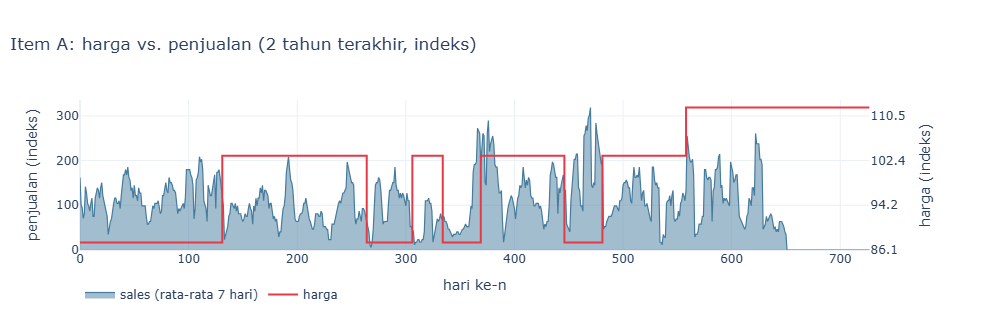

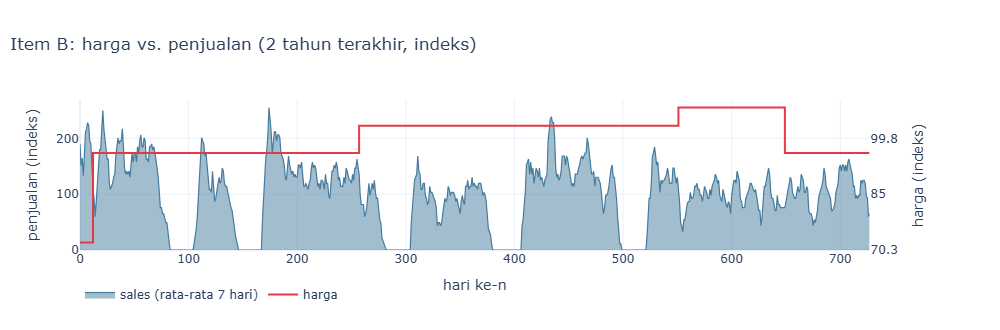

,n_changes,range_ratio
item,,
Item A,8,1.28
Item B,4,1.49
Item C,4,1.49
Item D,3,1.52
Item E,3,1.52


In [9]:
from forecasting.viz.anonymize import index_base, item_label, relative_days, to_index

# Examples: frequently-selling items with real price moves (>= 10% range) in the last 2 years
freq_items = classes.loc[classes["demand_class"].isin(["smooth", "erratic"]), "item_id"]
recent = open_sales[open_sales["item_id"].isin(freq_items) & (open_sales["d"] > LAST_D - 728)]
moves = recent.groupby("item_id", observed=True)["sell_price"].agg(
    n_changes=lambda p: int((p.diff().abs() > 0.009).sum()), range_ratio=lambda p: p.max() / p.min()
)
moves = moves[moves["range_ratio"] >= 1.10].sort_values(
    ["n_changes", "range_ratio"], ascending=False
)
examples = moves.head(2).index.tolist()
for i, item in enumerate(examples):
    ex = recent[recent["item_id"] == item].sort_values("date")
    ex = pd.DataFrame(
        {
            "date": relative_days(ex["date"], ex["date"].iloc[0]),
            "sales": to_index(ex["sales"].to_numpy(dtype=float), index_base(ex["sales"])),
            "sell_price": to_index(
                ex["sell_price"].to_numpy(dtype=float), index_base(ex["sell_price"])
            ),
        }
    )
    fig = plots.plot_price_vs_sales(
        ex, title=f"{item_label(i)}: harga vs. penjualan (2 tahun terakhir, indeks)"
    )
    fig.update_xaxes(title_text="hari ke-n")
    fig.update_yaxes(title_text="penjualan (indeks)", secondary_y=False)
    fig.update_yaxes(title_text="harga (indeks)", secondary_y=True)
    fig.show()
    if i == 0:
        plots.save_png(fig, "04b_price_example", config)
moves.head(5).round(2).set_axis([item_label(i) for i in range(5)], axis=0).rename_axis("item")

## Q5 · Kontribusi revenue (Pareto)

Revenue = unit terjual × harga jual, dihitung pada 364 hari terakhir sebelum periode test.

**Insight:** total revenue ±$5,12 juta per tahun. **1.246 item (40,9%) menyumbang 80% revenue**, jauh kurang terkonsentrasi dibanding aturan klasik 80/20. Dilihat per kelas demand (Q6), item **smooth hanya 7,8% dari jumlah item tetapi menyumbang 25,3% revenue**, sedangkan item intermittent tetap menyumbang porsi terbesar (58,3%).

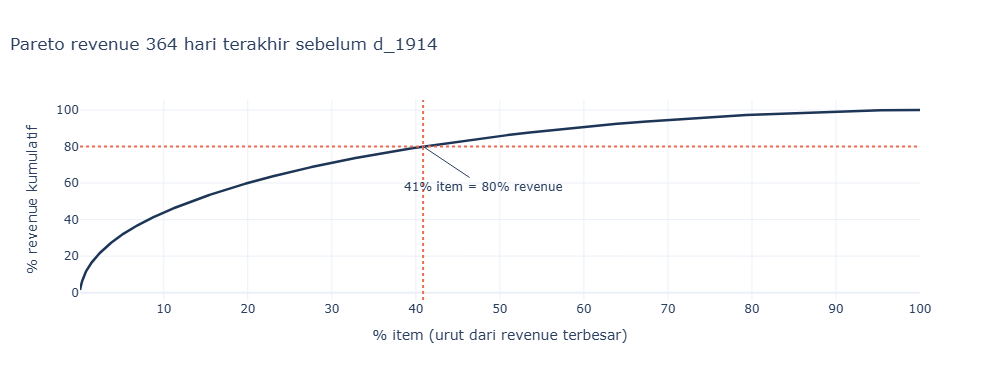

Total revenue: $5,121,080 | 1246 item (40.9%) = 80% revenue


demand_class
smooth                 25.30
erratic                 5.10
intermittent           58.30
lumpy                  11.40
insufficient_history    0.00
Name: revenue_share_pct, dtype: float32

In [10]:
win = config["eda"]["revenue_window_days"]
last_year = open_sales[open_sales["d"] > LAST_D - win]
rev = (
    last_year.assign(revenue=last_year["sales"] * last_year["sell_price"])
    .groupby("item_id", observed=True)["revenue"]
    .sum()
    .sort_values(ascending=False)
)
cum = rev.cumsum() / rev.sum()
n80 = int((cum < 0.8).sum()) + 1
fig = plots.plot_pareto(cum, title=f"Pareto revenue {win} hari terakhir sebelum d_{LAST_D + 1}")
fig.show()
plots.save_png(fig, "05_pareto_revenue", config)

rev_by_class = (
    rev.rename("revenue")
    .reset_index()
    .merge(classes[["item_id", "demand_class"]])
    .groupby("demand_class", observed=True)["revenue"]
    .sum()
)
print(f"Total revenue: ${rev.sum():,.0f} | {n80} item ({n80 / len(rev):.1%}) = 80% revenue")
(rev_by_class / rev_by_class.sum() * 100).round(1).rename("revenue_share_pct")

## Q6 · Klasifikasi demand Syntetos–Boylan

Setiap item diukur dengan dua angka (data ≤ d_1801, hari tutup diabaikan):
- **ADI** (*Average Demand Interval*) = jumlah hari / jumlah hari yang ada penjualannya. ADI = 1 berarti laku setiap hari, ADI = 3 berarti rata-rata laku sekali tiap 3 hari.
- **CV²** = (simpangan baku / rata-rata)², dihitung **hanya pada hari yang ada penjualan**. Kecil berarti jumlah per transaksi stabil, besar berarti jumlahnya acak.

| | CV² < 0,49 (jumlah stabil) | CV² ≥ 0,49 (jumlah acak) |
|---|---|---|
| **ADI < 1,32** (sering laku) | **Smooth** | **Erratic** |
| **ADI ≥ 1,32** (jarang laku) | **Intermittent** | **Lumpy** |

**Insight:** mayoritas item CA_1 **jarang laku**. Intermittent 71,9%, lumpy 17,5%, smooth hanya 7,8%, dan erratic 2,7%. Item intermittent rata-rata (median) laku sekali tiap ±2,8 hari. Hanya 2 item yang riwayatnya belum cukup (`insufficient_history`).

Per kategori: FOODS paling "sehat" (smooth 10,9%, lumpy 26,4%), sedangkan HOUSEHOLD (86,6% intermittent) dan HOBBIES (79,6%) hampir seluruhnya jarang laku. 9 item dengan CV² ekstrem (maksimum ≈ 20) sengaja dipotong dari sumbu-Y supaya pola item lain terlihat.

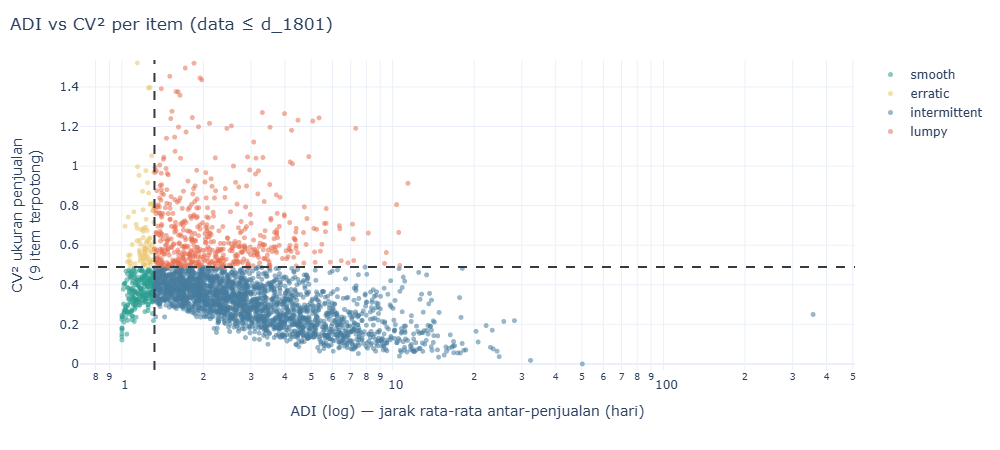

,n_item,pct
smooth,239,7.84
erratic,83,2.72
intermittent,2192,71.89
lumpy,533,17.48
insufficient_history,2,0.07


In [11]:
p = config["demand_class"]
fig = plots.plot_adi_cv2(
    classes,
    p["adi_threshold"],
    p["cv2_threshold"],
    title=f"ADI vs CV² per item (data ≤ d_{CLASS_CUTOFF})",
)
fig.show()
plots.save_png(fig, "06a_adi_cv2_scatter", config)

counts = classes["demand_class"].value_counts().reindex(classes["demand_class"].cat.categories)
pd.DataFrame({"n_item": counts, "pct": counts / counts.sum() * 100})

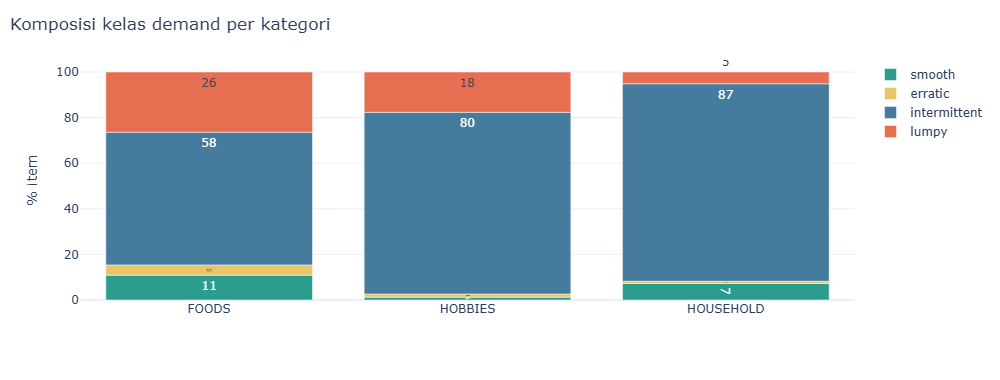

,adi,cv2
demand_class,,
smooth,1.17,0.37
erratic,1.22,0.60
intermittent,2.81,0.32
lumpy,2.03,0.61
insufficient_history,NaN,NaN


In [12]:
fig = plots.plot_class_share(
    classes[classes["demand_class"] != "insufficient_history"],
    title="Komposisi kelas demand per kategori",
)
fig.show()
plots.save_png(fig, "06b_class_share_by_cat", config)
classes.groupby("demand_class", observed=True)[["adi", "cv2"]].median().round(2)

## Q7 · Indikasi stockout (censored demand)

> **Censored demand**: data M5 mencatat *penjualan*, bukan *permintaan*. Kalau stok habis, penjualan tercatat 0 walaupun sebenarnya ada pembeli. Nol seperti ini "menyensor" demand yang sebenarnya.

Deret nol panjang (≥ 14 hari) dipisah menjadi dua jenis:
- **Pulih**: setelah nol berminggu-minggu, item laku lagi. Pada item yang biasanya laku setiap hari, ini indikasi kuat **stockout**.
- **Masih berlangsung di d_1913**: item masih nol di akhir periode train. Ini kemungkinan **discontinued** (berhenti dijual) padahal harganya masih tercantum.

**Insight:** di antara 322 item yang biasanya laku setiap hari (smooth + erratic), **203 item (63%) pernah nol ≥ 14 hari lalu laku lagi**, dengan median run 16 hari untuk smooth. Ini indikasi stockout yang cukup sering. Untuk item intermittent/lumpy, run panjang adalah hal biasa (median ±92–96 hari), jadi stockout tidak bisa dibedakan dari demand yang memang jarang. Selain itu, **272 item masih nol ≥ 14 hari di akhir periode train**.

In [13]:
thr = config["eda"]["stockout_zero_run_days"]
s = open_sales.sort_values(["item_id", "d"])
# Run that ENDED with a sale = length of the zero run just before a non-zero day (recovered)
prev_run = s.groupby("item_id", observed=True)["zero_run_len"].shift(1)
recovered = (
    prev_run[s["sales"] > 0]
    .groupby(s.loc[s["sales"] > 0, "item_id"], observed=True)
    .max()
    .rename("max_recovered_run")
)
# Run still ONGOING at the end of the training period (d_1913)
ongoing = s.groupby("item_id", observed=True)["zero_run_len"].last().rename("ongoing_run")

runs = classes.join(recovered, on="item_id").join(ongoing, on="item_id")
runs["recovered_long"] = runs["max_recovered_run"] >= thr
runs["ongoing_long"] = runs["ongoing_run"] >= thr
summary = runs.groupby("demand_class", observed=True).agg(
    n_item=("item_id", "size"),
    pct_recovered_long=("recovered_long", "mean"),
    median_recovered_run=("max_recovered_run", "median"),
    n_ongoing_long=("ongoing_long", "sum"),
)
summary["pct_recovered_long"] *= 100
summary

,n_item,pct_recovered_long,median_recovered_run,n_ongoing_long
demand_class,,,,
smooth,239,56.90,16.00,5
erratic,83,80.72,30.00,9
intermittent,2192,94.34,92.00,219
lumpy,533,95.12,96.00,39
insufficient_history,2,0.00,6.50,0


Item smooth/erratic (322): 203 pernah nol >= 14 hari lalu laku lagi (indikasi stockout), 14 masih nol >= 14 hari di d_1913 (kemungkinan discontinued)
Semua item: 272 item masih nol >= 14 hari di akhir periode train


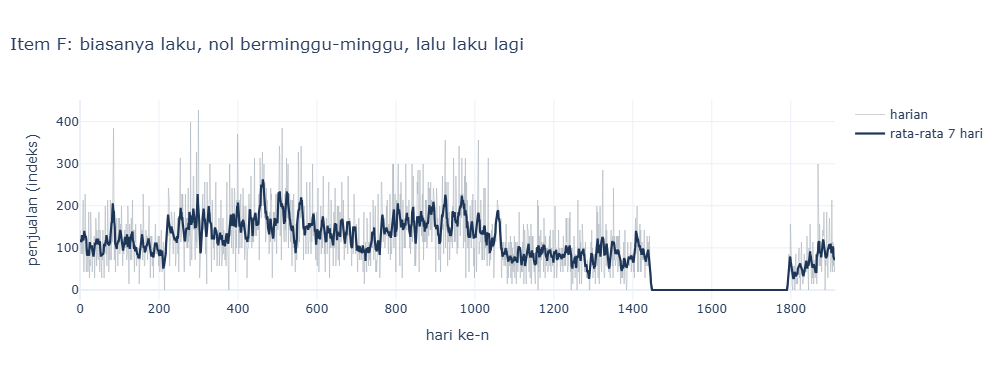

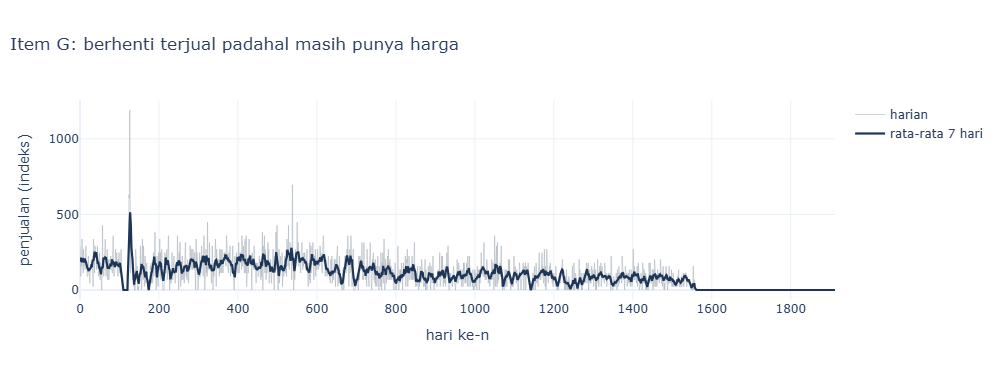

WindowsPath('C:/Projects/demand-forecasting-project/reports/figures/07b_discontinued_example.png')

In [14]:
freq_runs = runs[runs["item_id"].isin(freq_items)]
print(
    f"Item smooth/erratic ({len(freq_runs)}): "
    f"{freq_runs['recovered_long'].sum()} pernah nol >= {thr} hari lalu laku lagi (indikasi stockout), "
    f"{freq_runs['ongoing_long'].sum()} masih nol >= {thr} hari di d_{LAST_D} (kemungkinan discontinued)"
)
print(
    f"Semua item: {runs['ongoing_long'].sum()} item masih nol >= {thr} hari di akhir periode train"
)

ex_stockout = freq_runs.sort_values("max_recovered_run", ascending=False).iloc[0]["item_id"]
ex_disc = freq_runs.sort_values("ongoing_run", ascending=False).iloc[0]["item_id"]


def indexed(item: str) -> pd.DataFrame:
    ex = open_sales[open_sales["item_id"] == item].sort_values("date")
    return pd.DataFrame(
        {
            "date": relative_days(ex["date"], ex["date"].iloc[0]),
            "sales": to_index(ex["sales"].to_numpy(dtype=float), index_base(ex["sales"])),
        }
    )


fig = plots.plot_daily_with_trend(
    indexed(ex_stockout),
    window=7,
    title=f"{item_label(5)}: biasanya laku, nol berminggu-minggu, lalu laku lagi",
)
fig.update_xaxes(title_text="hari ke-n")
fig.update_yaxes(title_text="penjualan (indeks)")
fig.show()
plots.save_png(fig, "07a_stockout_example", config)
fig = plots.plot_daily_with_trend(
    indexed(ex_disc),
    window=7,
    title=f"{item_label(6)}: berhenti terjual padahal masih punya harga",
)
fig.update_xaxes(title_text="hari ke-n")
fig.update_yaxes(title_text="penjualan (indeks)")
fig.show()
plots.save_png(fig, "07b_discontinued_example", config)

## Q8 · Pemilihan toko

Perbandingan cepat 10 toko (data ≤ d_1913): volume, pertumbuhan tahun terakhir, proporsi item-hari bernilai nol, dan jumlah hari toko tidak menjual apa pun.

**Insight:** CA_1 berada di **peringkat 3 volume** (±4.436 unit/hari, di bawah CA_3 dan WI_2), **pertumbuhannya stabil** (+2% YoY, tanpa structural break), dan proporsi nolnya di tengah (55,7%). Toko lain punya masalah: **CA_2 melonjak +50% YoY** (indikasi renovasi/ekspansi, alias structural break) dan **WI_3 +22%**. CA_3 punya volume tertinggi dan nol paling sedikit (49,9%), jadi bisa menjadi alternatif, tetapi justru kurang mewakili tantangan intermittency yang menjadi inti project ini.

**Keputusan:** tetap memakai **CA_1** (D-002 dikonfirmasi): stabil, volume tinggi, dan representatif.

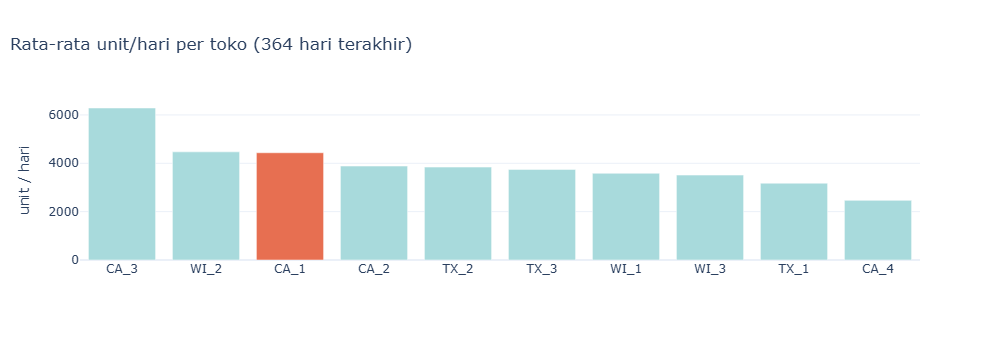

,n_items,mean_daily_units,mean_daily_units_last,yoy_growth_last,pct_zero_item_days_last,zero_sales_days
store_id,,,,,,
CA_1,3049,"4,024.16","4,436.04",0.02,55.67,5
CA_2,3049,"2,972.02","3,885.04",0.50,57.15,0
CA_3,3049,"5,848.50","6,286.76",-0.01,49.88,1
CA_4,3049,"2,145.15","2,466.81",0.06,65.32,5
TX_1,3049,"2,924.88","3,176.33",0.04,64.50,3
TX_2,3049,"3,771.24","3,842.22",0.05,60.01,3
TX_3,3049,"3,183.13","3,745.82",0.08,61.80,0
WI_1,3049,"2,691.62","3,586.77",0.08,57.75,3
WI_2,3049,"3,420.81","4,473.11",0.12,60.53,2


In [15]:
overview = store_overview(config, last_d=LAST_D, window_days=win)
fig = plots.plot_store_comparison(
    overview,
    "mean_daily_units_last",
    highlight=STORE,
    title=f"Rata-rata unit/hari per toko ({win} hari terakhir)",
    axis_title="unit / hari",
)
fig.show()
plots.save_png(fig, "08_store_comparison", config)
overview.set_index("store_id").round(2)

## Key findings → implikasi ke modeling

| # | Temuan | Implikasi ke modeling |
|---|---|---|
| 1 | Tren naik tetapi melambat ke ±0% (2015–2016), tanpa structural break | Seluruh history bisa dipakai. Level terbaru lebih penting daripada tren panjang, sehingga rolling mean dan lag (28–56 hari) cocok. |
| 2 | **Seasonality mingguan sangat kuat** (akhir pekan +25–34%, tengah minggu −10–20%) | **Seasonal Naive (lag 7) wajib menjadi baseline**. `day_of_week` dan `is_weekend` menjadi fitur penting. Seasonal period = 7 untuk ETS/SARIMAX. |
| 3 | Seasonality tahunan lemah–sedang (±8–18%), puncak musim panas | `month`, `week_of_year`, dan `lag_364` layak dicoba. Prophet yearly seasonality relevan di level agregat. |
| 4 | Efek event berbeda arah per event (−22% s/d +30%), SNAP +13% di FOODS | Pakai `event_name`/`event_type` sebagai kategori, bukan flag 0/1. `snap` dan `days_to_next_event` menjadi fitur. |
| 5 | Harga turun lalu unit naik (±+14 poin), tetapi perubahan harga jarang (±0,6% minggu) | Fitur harga relatif (perubahan vs minggu lalu, momentum, rasio vs rata-rata) berguna tetapi kontribusinya kemungkinan kecil. Akan dicek lewat ablation di Fase 5. |
| 6 | 41% item = 80% revenue. Smooth = 7,8% item tetapi 25% revenue | **WRMSSE-lite berbobot revenue** tepat dipakai, karena item intermittent tetap 58% revenue sehingga tidak bisa diabaikan. |
| 7 | **89% item intermittent/lumpy**, hanya 8% smooth | Model yang mengasumsikan data kontinu (ETS/ARIMA/Prophet) kemungkinan lemah di level item. LightGBM dengan objective **tweedie/poisson** lebih cocok untuk data banyak nol. Sampel statistik 200 item (50 per kelas) **tidak proporsional** terhadap populasi, jadi ini harus diingat saat membaca rata-rata. |
| 8 | 63% item yang biasanya laku pernah nol ≥ 2 minggu lalu pulih (stockout). 272 item masih nol di akhir train | `zero_run_len` (di-shift 28 hari) menjadi fitur. Censored demand ditulis sebagai **limitasi** di README. Di simulasi inventori (Fase 7), demand = sales berarti demand sebenarnya *under-estimated*. |
| 9 | CA_1 stabil, volume tinggi, representatif | Scope tetap: **CA_1** (D-002). |